# Semantic video retrieval: data, representations and learned ranking

This notebook contains the working preparation, pretrained encoding, temporal scorer and residual-adapter training algorithms. Code cells are readable copies of the named production modules; the source SHA records which implementation was copied. Production modules remain authoritative.

Executed cells below inspect the real licensed DiDeMo subset and replay the completed two-query checkpoint. They do not load CLIP locally, train the full study or open test descriptions. The full CPU experiment is running; no full benchmark result is implied by its mechanics smoke.

In [1]:
from pathlib import Path
import json,hashlib,collections
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,HTML
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
assert (ROOT/'src').exists()
import os
os.chdir(ROOT)
def read(path):return json.loads(Path(path).read_text(encoding='utf-8'))
def table(rows,title):
    if not rows:return
    columns=list(rows[0]);html='<h4>'+title+'</h4><table><tr>'+''.join('<th>'+c+'</th>' for c in columns)+'</tr>'
    for row in rows:html+='<tr>'+''.join('<td>'+str(row[c])+'</td>' for c in columns)+'</tr>'
    display(HTML(html+'</table>'))
def save_plot(name):
    plt.tight_layout();Path('docs/figures').mkdir(exist_ok=True)
    plt.savefig('docs/figures/'+name+'.png',dpi=150)
    plt.show()
SOURCE=Path('data/processed/didemo-v2')
CACHE=Path('data/interim/cloud-smoke-output-v1/video-smoke')
RUN_ENCODER=False
RUN_TRAINING=False
RUN_TEST=False


## 1. Real data and frozen split
The source cohort is availability-filtered, not the full official benchmark. Identical validation media are coalesced. One geometrically invalid training source was excluded before any training or score.

In [2]:
manifest=read(SOURCE/'manifest.json')
for name,expected in manifest['files'].items():
    assert hashlib.sha256((SOURCE/name).read_bytes()).hexdigest()==expected
assert not (SOURCE/'test.json').exists()
table([{'split':s,**r} for s,r in manifest['counts'].items()],'Verified staged cohort')
print('Source revision:',manifest['source_revision'])
print('Staging manifest SHA256:',hashlib.sha256((SOURCE/'manifest.json').read_bytes()).hexdigest())


split,source_video_ids,unique_media,queries,test_targets_staged
train,364,364,1390,False
val,74,73,261,False
test,47,47,None,False


Source revision: b6a555c8134581305d0ed4716fbc192860e0b88c
Staging manifest SHA256: 8d59cd76696086e3d37e5642454400c52a7fbe8a2fefae004116b0802b43c0b0


In [3]:
"""Freeze licensed, downloaded DiDeMo train/validation sources without test gold."""

import argparse,hashlib,json,math

from pathlib import Path

from src.data.didemo import HASHES,REVISION

from src.models.moments import interval,moments

def stage(output, directory='data/external/didemo', receipts='data/interim/didemo-expanded-downloads/receipts.jsonl', selection='data/interim/didemo-expanded-selection.json', decoder_preflight=None):
    output=Path(output)
    if output.exists():raise ValueError('Refuse to overwrite frozen preparation')
    directory=Path(directory);receipt_path=Path(receipts);selection_path=Path(selection)
    plan=json.loads(selection_path.read_text(encoding='utf-8'))
    permitted={(split,r['video']):r for split,rows in plan['splits'].items() for r in rows}
    available={}
    for line in receipt_path.read_text(encoding='utf-8').splitlines():
        row=json.loads(line)
        if row['status']!='complete':continue
        key=(row['split'],row['video'])
        if key not in permitted:raise ValueError('Receipt outside frozen selection')
        if key in available and available[key]['sha256']!=row['sha256']:raise ValueError('Conflicting media receipts')
        available[key]=row
    excluded=set();decoder_hash=None
    if decoder_preflight is not None:
        decoder_path=Path(decoder_preflight);decoder_hash=hashlib.sha256(decoder_path.read_bytes()).hexdigest()
        decoded=json.loads(decoder_path.read_text(encoding='utf-8'));seen=set()
        for row in decoded['rows']:
            key=(row['split'],row['video'])
            if key not in available:raise ValueError('Decoder source outside frozen availability cohort')
            expected=available[key]['sha256']
            if row.get('sha256',expected)!=expected:raise ValueError('Decoder source hash mismatch')
            if expected in seen:raise ValueError('Duplicate decoder inspection')
            seen.add(expected)
            duration=row.get('duration',0);fps=row.get('fps',0);segments=row.get('num_segments',0)
            valid=type(segments) is int and 1<=segments<=6 and all(isinstance(v,(int,float)) and math.isfinite(v) and v>0 for v in (duration,fps)) and duration>(segments-1)*5
            if not valid:excluded.add(expected)
        if seen!={r['sha256'] for r in available.values()}:raise ValueError('Incomplete decoder coverage')
        available={key:r for key,r in available.items() if r['sha256'] not in excluded}
    counts={split:sum(key[0]==split for key in available) for split in ('train','val','test')}
    if any(counts[s]<n for s,n in [('train',100),('val',20),('test',40)]):raise ValueError('Insufficient available videos')
    content_groups={}
    for key,row in available.items():content_groups.setdefault(row['sha256'],[]).append(key)
    if any(len({key[0] for key in group})>1 for group in content_groups.values()):
        raise ValueError('Exact media content crosses source splits')
    aliases={key:min(group)[1] for group in content_groups.values() for key in group}
    alias_copies=sum(len(group)-1 for group in content_groups.values())
    staged={};media=[];diagnostics={}
    for split in ('train','val','test'):
        path=directory/f'{split}_data.json'
        if hashlib.sha256(path.read_bytes()).hexdigest()!=HASHES[path.name]:raise ValueError('Changed official metadata')
        rows=json.loads(path.read_text(encoding='utf-8'))
        queries=[];seen_videos={};seen_ids=set()
        for source_index,row in enumerate(rows):
            key=(split,row['video'])
            if key not in available:continue
            n=row['num_segments'];moments(n)
            if row['video'] in seen_videos and seen_videos[row['video']]!=n:raise ValueError('Inconsistent video geometry')
            seen_videos[row['video']]=n
            if split=='test':continue  # Do not copy descriptions, target intervals or annotation IDs.
            identity=f'{split}:{source_index}:{row["annotation_id"]}'
            if identity in seen_ids:raise ValueError('Duplicate stable row identity')
            seen_ids.add(identity)
            times=[list(interval(t)) for t in row['times']]
            if not times or any(t[1]>=n for t in times):raise ValueError('Invalid human annotation geometry')
            text=row['description']
            if not isinstance(text,str) or not text.strip():raise ValueError('Empty human description')
            queries.append({'id':identity,'video':aliases[key],'source_video':row['video'],'text':text,'times':times})
        if len(seen_videos)!=counts[split]:raise ValueError('Receipt not represented by official split')
        canonical_geometry={}
        for name,n in seen_videos.items():
            canonical=aliases[(split,name)]
            if canonical in canonical_geometry and canonical_geometry[canonical]!=n:
                raise ValueError('Identical media with inconsistent annotated geometry')
            canonical_geometry[canonical]=n
        for name,n in sorted(canonical_geometry.items()):
            receipt=available[(split,name)];source=permitted[(split,name)]
            media.append({'split':split,'video':name,'num_segments':n,'sha256':receipt['sha256'],
                'bytes':receipt['bytes'],'aws_url':source['aws_url'],'license':source['license'],
                'original_url':source['original_url']})
        if split!='test':staged[f'{split}.json']=queries
        diagnostics[split]={'source_video_ids':len(seen_videos),'unique_media':len(canonical_geometry),'queries':len(queries) if split!='test' else None,
                            'test_targets_staged':False}
    staged['media.json']=media
    output.mkdir(parents=True,exist_ok=False)
    hashes={}
    for name,value in staged.items():
        content=(json.dumps(value,ensure_ascii=False,indent=2)+'\n').encode('utf-8')
        (output/name).write_bytes(content);hashes[name]=hashlib.sha256(content).hexdigest()
    manifest={'source_revision':REVISION,'official_metadata_sha256':HASHES,
        'receipt_sha256':hashlib.sha256(receipt_path.read_bytes()).hexdigest(),
        'selection_file_sha256':hashlib.sha256(selection_path.read_bytes()).hexdigest(),
        'files':hashes,'counts':diagnostics,'raw_media_redistributed':False,
        'decoder_preflight_sha256':decoder_hash,'excluded_decoder_media_sha256':sorted(excluded),
        'within_split_alias_copies':alias_copies,'alias_policy':'same-SHA video IDs coalesced; all human queries retained',
        'test_target_policy':'test JSON read only for video geometry; captions/intervals never staged',
        'availability_bias':'Fixed available CC subset; not full official benchmark; no score-based replacements'}
    (output/'manifest.json').write_bytes((json.dumps(manifest,indent=2)+'\n').encode())
    print(json.dumps(manifest,indent=2));return manifest

## 2. Pinned CLIP and temporal pooling
CLIP image/text weights are frozen. Two real frames per five-second bin are encoded; contiguous-bin averages form normalized candidate moment vectors. The loader rejects missing or mismatched weights. Defining the class does not download or allocate the encoder.

In [4]:
"""Pinned CLIP inference with verified pretrained weights and loading diagnostics."""

import hashlib

import numpy as np

from src.config import MODEL_ID, MODEL_REVISION

WEIGHTS_SHA256='a63082132ba4f97a80bea76823f544493bffa8082296d62d71581a4feff1576f'

class CLIPEncoder:
    def __init__(self,device='cpu'):
        import torch
        from transformers import CLIPModel,CLIPProcessor
        from huggingface_hub import hf_hub_download
        torch.set_num_threads(2)
        self.torch=torch;self.device=device
        try:
            weights=hf_hub_download(MODEL_ID,'pytorch_model.bin',revision=MODEL_REVISION,local_files_only=True)
        except OSError:
            weights=hf_hub_download(MODEL_ID,'pytorch_model.bin',revision=MODEL_REVISION)
        with open(weights,'rb') as handle:digest=hashlib.file_digest(handle,'sha256').hexdigest()
        if digest!=WEIGHTS_SHA256:raise ValueError('Pinned CLIP weight hash mismatch')
        try:
            model,info=CLIPModel.from_pretrained(MODEL_ID,revision=MODEL_REVISION,use_safetensors=False,
                output_loading_info=True,local_files_only=True)
        except OSError:
            model,info=CLIPModel.from_pretrained(MODEL_ID,revision=MODEL_REVISION,use_safetensors=False,
                output_loading_info=True)
        if any(info.get(k) for k in ('missing_keys','unexpected_keys','mismatched_keys','error_msgs')):
            raise ValueError('Incomplete or incompatible pretrained CLIP loading')
        self.model=model.to(device).eval()
        try:
            self.processor=CLIPProcessor.from_pretrained(MODEL_ID,revision=MODEL_REVISION,use_fast=False,local_files_only=True)
        except OSError:
            self.processor=CLIPProcessor.from_pretrained(MODEL_ID,revision=MODEL_REVISION,use_fast=False)
        self.receipt={'model_id':MODEL_ID,'revision':MODEL_REVISION,'weights_sha256':digest,'loading_info':info}
    def _normalize(self,values):
        values=values/values.norm(dim=-1,keepdim=True)
        result=values.cpu().numpy().astype(np.float32)
        if not np.isfinite(result).all():raise ValueError('Nonfinite encoder features')
        return result
    def images(self,images):
        if not images:raise ValueError('No frames')
        inputs=self.processor(images=images,return_tensors='pt').to(self.device)
        with self.torch.inference_mode():return self._normalize(self.model.get_image_features(**inputs))
    def texts(self,queries):
        if not queries or any(not isinstance(q,str) or not q.strip() for q in queries):
            raise ValueError('Nonempty text queries required')
        inputs=self.processor(text=queries,padding=True,truncation=True,return_tensors='pt').to(self.device)
        with self.torch.inference_mode():return self._normalize(self.model.get_text_features(**inputs))
    def text(self,query):return self.texts([query])[0]

In [5]:
"""Encode authentic DiDeMo videos and train/validation text; no test targets needed."""

import argparse,hashlib,json,math,time

from pathlib import Path

import numpy as np

from src.models.encoder import CLIPEncoder

from src.models.moments import moments

def digest(path):
    with Path(path).open('rb') as handle:return hashlib.file_digest(handle,'sha256').hexdigest()

def frame_schedule(segments,duration,fps):
    moments(segments)
    if not all(math.isfinite(v) and v>0 for v in (duration,fps)) or duration <= (segments-1)*5:
        raise ValueError('Invalid or annotation-inconsistent duration/FPS')
    schedule=[]
    for segment in range(segments):
        start=segment*5.;end=min((segment+1)*5.,duration)
        for fraction in (.25,.75):
            timestamp=start+(end-start)*fraction
            frame=int(math.floor(timestamp*fps))
            schedule.append({'segment':segment,'frame':frame,'seconds':frame/fps})
    return schedule

def encode(source,media,output,smoke=False,device='cpu'):
    import imageio.v2 as imageio
    from PIL import Image
    source=Path(source);media=Path(media);output=Path(output)
    if output.exists():raise ValueError('Refuse to overwrite encoder cache')
    manifest=json.loads((source/'manifest.json').read_text(encoding='utf-8'))
    for name,expected in manifest['files'].items():
        if digest(source/name)!=expected:raise ValueError('Changed staged source: '+name)
    records=json.loads((source/'media.json').read_text(encoding='utf-8'))
    queries={s:json.loads((source/f'{s}.json').read_text(encoding='utf-8')) for s in ('train','val')}
    if smoke:
        chosen={s:next(r['video'] for r in records if r['split']==s) for s in ('train','val')}
        records=[r for r in records if r['split'] in chosen and r['video']==chosen[r['split']]]
        queries={s:[q for q in rows if q['video']==chosen[s]][:2] for s,rows in queries.items()}
    output.mkdir(parents=True,exist_ok=False)
    encoder=CLIPEncoder(device);start=time.monotonic();vectors={};candidates={};frame_receipts=[]
    for split in ('train','val','test'):
        embeddings=[];rows=[]
        for record in records:
            if record['split']!=split:continue
            path=media/record['video']
            if digest(path)!=record['sha256']:raise ValueError('Changed media source')
            reader=imageio.get_reader(path,format='ffmpeg')
            try:
                meta=reader.get_meta_data();fps=float(meta['fps']);duration=float(meta['duration'])
                schedule=frame_schedule(record['num_segments'],duration,fps)
                images=[Image.fromarray(reader.get_data(item['frame'])).convert('RGB') for item in schedule]
            finally:reader.close()
            frame_values=encoder.images(images)
            segments=frame_values.reshape(record['num_segments'],2,-1).mean(axis=1)
            for a,b in moments(record['num_segments']):
                value=segments[a:b+1].mean(axis=0);value=value/np.linalg.norm(value)
                embeddings.append(value);rows.append({'video':record['video'],'moment':[a,b]})
            frame_receipts.append({'video':record['video'],'split':split,'source_sha256':record['sha256'],
                'duration':duration,'fps':fps,'samples':schedule})
            print(json.dumps({'encoded_videos':len(frame_receipts),'total_videos':len(records)}),flush=True)
        if embeddings:
            vectors[split]=np.stack(embeddings).astype(np.float32);candidates[split]=rows
    file_hashes={};truncation={}
    for split in vectors:
        path=output/f'{split}-moments.npy';np.save(path,vectors[split],allow_pickle=False);file_hashes[path.name]=digest(path)
        path=output/f'{split}-candidates.json';path.write_bytes((json.dumps(candidates[split],indent=2)+'\n').encode());file_hashes[path.name]=digest(path)
    for split,rows in queries.items():
        texts=[q['text'] for q in rows];pieces=[]
        for offset in range(0,len(texts),32):pieces.append(encoder.texts(texts[offset:offset+32]))
        values=np.concatenate(pieces)
        lengths=[len(ids) for ids in encoder.processor.tokenizer(texts,truncation=False)['input_ids']]
        truncation[split]={'queries':len(rows),'over_token_limit':sum(n>77 for n in lengths),'maximum_tokens':max(lengths)}
        path=output/f'{split}-text.npy';np.save(path,values,allow_pickle=False);file_hashes[path.name]=digest(path)
        path=output/f'{split}-queries.json';path.write_bytes((json.dumps(rows,ensure_ascii=False,indent=2)+'\n').encode('utf-8'));file_hashes[path.name]=digest(path)
    # Actual pretrained output replay after disk serialization.
    replay_query=queries['val'][0]['text'];replay=encoder.text(replay_query)
    saved=np.load(output/'val-text.npy',allow_pickle=False)[0]
    error=float(np.max(np.abs(replay-saved)))
    if error>1e-5:raise ValueError('Saved pretrained embedding replay mismatch')
    path=output/'frames.json';path.write_bytes((json.dumps(frame_receipts,indent=2)+'\n').encode());file_hashes[path.name]=digest(path)
    receipt={'encoder':encoder.receipt,'files':file_hashes,'source_manifest_sha256':digest(source/'manifest.json'),
        'smoke_only':smoke,'seconds':time.monotonic()-start,'videos':len(records),'text_truncation':truncation,
        'actual_text_replay_max_abs_error':error,'test_text_or_targets_encoded':False,
        'splits':{s:{'moments':len(v),'dimension':v.shape[1]} for s,v in vectors.items()}}
    (output/'manifest.json').write_bytes((json.dumps(receipt,indent=2,allow_nan=False)+'\n').encode())
    print(json.dumps(receipt,indent=2));return receipt

In [6]:
if RUN_ENCODER:
    encode(SOURCE,Path('data/raw/didemo'),Path('data/processed/new-encoder-cache'),smoke=False,device='cpu')
else:
    receipt=read('docs/video-smoke.json')
    table([{'real videos':receipt['real_videos'],'encoder seconds excluding loading':receipt['feature_seconds_excluding_model_load'],
            'embedding replay max abs error':receipt['feature_replay_max_abs_error']}],'Actual completed encoder smoke')
    print('Pinned encoder:',receipt['encoder'])


real videos,encoder seconds excluding loading,embedding replay max abs error
2,5.968649001000017,2.9802322387695312e-08


Pinned encoder: {'model_id': 'openai/clip-vit-base-patch32', 'revision': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'weights_sha256': 'a63082132ba4f97a80bea76823f544493bffa8082296d62d71581a4feff1576f', 'loading_info': {'missing_keys': [], 'unexpected_keys': [], 'mismatched_keys': [], 'error_msgs': []}}


## 3. Human temporal references and metrics
Corpus consensus recall requires both the correct video and temporal overlap. It is a custom metric. Official within-video metrics are reported separately. Repeated human intervals are retained; ties never consult targets.

In [7]:
"""Temporal retrieval metrics for inclusive DiDeMo five-second bin intervals.

Corpus consensus recall is a custom metric. Official within-video metrics follow
LisaAnne/LocalizingMoments utils/eval.py at the pinned data revision.
"""

import numpy as np

def interval(value):
    if not isinstance(value, (list, tuple)) or len(value) != 2:
        raise ValueError('Expected inclusive start/end bins')
    a,b=value
    if type(a) is not int or type(b) is not int or not 0 <= a <= b < 6:
        raise ValueError('Invalid DiDeMo bin interval')
    return a,b

def moments(num_segments):
    if type(num_segments) is not int or not 1 <= num_segments <= 6:
        raise ValueError('Expected one through six segments')
    return [(a,b) for a in range(num_segments) for b in range(a,num_segments)]

def iou(prediction, reference):
    a,b=interval(prediction);c,d=interval(reference)
    return max(0,min(b,d)+1-max(a,c))/(max(b,d)+1-min(a,c))

def consensus_iou(prediction, references):
    if not references:raise ValueError('Missing human temporal references')
    values=sorted(iou(prediction,ref) for ref in references)
    return float(np.mean(values[-3:]))

def positive_mask(candidates, query):
    return np.asarray([c['video']==query['video'] and
        consensus_iou(c['moment'],query['times']) >= .5 for c in candidates],dtype=bool)

def evaluate(scores, candidates, queries):
    scores=np.asarray(scores)
    if scores.shape != (len(queries),len(candidates)) or not queries or not candidates:
        raise ValueError('Nonempty query by candidate score matrix required')
    if not np.isfinite(scores).all():raise ValueError('Nonfinite retrieval scores')
    keys=[(c['video'],interval(c['moment'])) for c in candidates]
    if len(set(keys))!=len(keys):raise ValueError('Duplicate candidate moments')
    corpus1=[];corpus5=[];video1=[];video5=[];local1=[];local5=[];local_iou=[];attainable=[]
    for row,q in zip(scores,queries):
        refs=[interval(t) for t in q['times']]
        if not refs:raise ValueError('Missing temporal references')
        order=np.argsort(-row,kind='stable')
        local=[i for i in order if candidates[i]['video']==q['video']]
        if not local:raise ValueError('Correct video absent from candidate corpus')
        local_moments=[keys[i][1] for i in local]
        if any(t not in local_moments for t in refs):
            raise ValueError('Human reference missing from candidate geometry')
        positives=positive_mask(candidates,q)
        corpus1.append(bool(positives[order[0]]));corpus5.append(bool(positives[order[:5]].any()))
        video1.append(candidates[order[0]]['video']==q['video'])
        video5.append(any(candidates[i]['video']==q['video'] for i in order[:5]))
        ranks=sorted(local_moments.index(t)+1 for t in refs)
        average_rank=float(np.mean(ranks[:3]))
        local1.append(average_rank <= 1);local5.append(average_rank <= 5)
        local_iou.append(consensus_iou(local_moments[0],refs));attainable.append(bool(positives.any()))
    mean=lambda x:float(np.mean(x))
    return {'queries':len(queries),'candidate_moments':len(candidates),
        'corpus_consensus_r1_iou50':mean(corpus1),'corpus_consensus_r5_iou50':mean(corpus5),
        'corpus_video_r1':mean(video1),'corpus_video_r5':mean(video5),
        'within_video_official_rank1':mean(local1),'within_video_official_rank5':mean(local5),
        'within_video_official_miou':mean(local_iou),
        'consensus_attainable_fraction':mean(attainable),
        'metric_scope':'licensed available subset; corpus metrics custom; within-video formula official',
        'tie_rule':'stable original candidate order; no gold-dependent tie breaking'}

## 4. Model, loss, optimizer and selection
The residual 512→64→512 text adapter starts at identity. Multi-positive contrastive loss is trained against frozen visual moments. Three learning/decay procedures use three seeds each; equal-seed score means, not the best seed, compete with frozen CLIP. Validation-only promotion requires at least .01 corpus recall gain and no more than .01 within-video IoU loss.

In [8]:
"""Frozen-protocol residual text adapters, selected without test targets."""

import argparse,hashlib,json,time

from pathlib import Path

import numpy as np

import torch

from torch import nn

from src.models.moments import evaluate,positive_mask

CONFIGS=[{'name':'lr001','lr':.001,'weight_decay':.01},
         {'name':'lr0003','lr':.0003,'weight_decay':.01},
         {'name':'decay01','lr':.001,'weight_decay':.1}]

SEEDS=[42,1337,2026]

class Adapter(nn.Module):
    def __init__(self):
        super().__init__();self.down=nn.Linear(512,64);self.up=nn.Linear(64,512)
        nn.init.zeros_(self.up.weight);nn.init.zeros_(self.up.bias)
    def forward(self,x):return nn.functional.normalize(x+self.up(nn.functional.gelu(self.down(x))),dim=-1)

def digest(path):
    with Path(path).open('rb') as f:return hashlib.file_digest(f,'sha256').hexdigest()

def load_cache(path,allow_smoke=False):
    path=Path(path);manifest=json.loads((path/'manifest.json').read_text())
    if manifest['smoke_only'] and not allow_smoke:raise ValueError('Smoke cache cannot support benchmark training')
    for name,expected in manifest['files'].items():
        if digest(path/name)!=expected:raise ValueError('Changed feature cache')
    result={}
    for split in ('train','val'):
        x=np.load(path/f'{split}-text.npy',allow_pickle=False);v=np.load(path/f'{split}-moments.npy',allow_pickle=False)
        q=json.loads((path/f'{split}-queries.json').read_text(encoding='utf-8'))
        c=json.loads((path/f'{split}-candidates.json').read_text())
        if x.shape!=(len(q),512) or v.shape!=(len(c),512):raise ValueError('Feature shape mismatch')
        if not np.isfinite(x).all() or not np.isfinite(v).all():raise ValueError('Nonfinite cached features')
        if not np.allclose(np.linalg.norm(x,axis=1),1,atol=1e-4) or not np.allclose(np.linalg.norm(v,axis=1),1,atol=1e-4):raise ValueError('Unnormalized CLIP features')
        result[split]={'x':torch.from_numpy(x),'v':torch.from_numpy(v),'queries':q,'candidates':c,
                       'positive':torch.from_numpy(np.stack([positive_mask(c,row) for row in q]))}
    return result,manifest

def multipositive_loss(scores,positives):
    if scores.shape!=positives.shape or not positives.any(dim=1).all():raise ValueError('Missing contrastive positive')
    return (torch.logsumexp(scores,dim=1)-torch.logsumexp(scores.masked_fill(~positives,float('-inf')),dim=1)).mean()

def scores_for(states,x,v):
    if not states:return (x@v.T).numpy()
    scores=[]
    for state in states:
        model=Adapter();model.load_state_dict(state,strict=True);model.eval()
        with torch.inference_mode():scores.append((model(x)@v.T).numpy())
    return np.mean(scores,axis=0)

def train(cache,output):
    torch.set_num_threads(2);torch.use_deterministic_algorithms(True)
    output=Path(output)
    if output.exists():raise ValueError('Preserve prior training evidence; use a fresh output directory')
    data,manifest=load_cache(cache);output.mkdir(parents=True,exist_ok=False)
    training=data['train'];validation=data['val'];valid=training['positive'].any(dim=1)
    x=training['x'][valid];positive=training['positive'][valid];v=training['v']
    if len(x)==0:raise ValueError('No training query has a consensus-positive moment')
    baseline_scores=scores_for([],validation['x'],validation['v'])
    baseline=evaluate(baseline_scores,validation['candidates'],validation['queries'])
    baseline_name='frozen_clip';winner_states=[];winner_metrics=baseline;winner_name=baseline_name
    reports=[];start=time.monotonic();best_promoted=-1.
    for config in CONFIGS:
        states=[];seed_reports=[]
        for seed in SEEDS:
            torch.manual_seed(seed);rng=torch.Generator().manual_seed(seed)
            model=Adapter();optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],weight_decay=config['weight_decay'])
            best=-1.;best_state=None;best_epoch=0;history=[]
            for epoch in range(1,51):
                model.train();order=torch.randperm(len(x),generator=rng);total=0.
                for indices in order.split(64):
                    optimizer.zero_grad();logits=model(x[indices])@v.T/.07
                    loss=multipositive_loss(logits,positive[indices]);loss.backward();optimizer.step()
                    total+=float(loss.detach())*len(indices)
                model.eval()
                with torch.inference_mode():ranked=(model(validation['x'])@validation['v'].T).argmax(dim=1)
                primary=float(validation['positive'][torch.arange(len(ranked)),ranked].float().mean())
                history.append({'epoch':epoch,'train_loss':total/len(x),'validation_corpus_consensus_r1_iou50':primary})
                if primary>best:
                    best=primary;best_epoch=epoch;best_state={k:t.detach().clone() for k,t in model.state_dict().items()}
                print(json.dumps({'config':config['name'],'seed':seed,**history[-1]}),flush=True)
                if epoch>=5 and epoch-best_epoch>=8:break
            states.append(best_state);torch.save({'state':best_state,'config':config,'seed':seed,'best_epoch':best_epoch},output/f'{config["name"]}-{seed}.pt')
            seed_reports.append({'seed':seed,'best_epoch':best_epoch,'history':history})
        score=scores_for(states,validation['x'],validation['v']);metrics=evaluate(score,validation['candidates'],validation['queries'])
        primary=metrics['corpus_consensus_r1_iou50']
        eligible=primary-baseline['corpus_consensus_r1_iou50']>=.01-1e-12 and metrics['within_video_official_miou']>=baseline['within_video_official_miou']-.01-1e-12
        reports.append({'config':config,'seeds':seed_reports,'validation':metrics,'promotion_eligible':eligible})
        if eligible and primary>best_promoted:
            best_promoted=primary;winner_name=config['name'];winner_states=states;winner_metrics=metrics
    rng=np.random.default_rng(42)
    random=evaluate(rng.random(baseline_scores.shape),validation['candidates'],validation['queries'])
    chronology=evaluate(np.broadcast_to(-np.arange(baseline_scores.shape[1],dtype=float),baseline_scores.shape),validation['candidates'],validation['queries'])
    selection={'schema':1,'winner':winner_name,'states':winner_states,'encoder':manifest['encoder'],
        'cache_manifest_sha256':digest(Path(cache)/'manifest.json'),'validation':winner_metrics,
        'training_consensus_no_positive_queries':int((~valid).sum()),'test_targets_used':False}
    torch.save(selection,output/'selected.pt');reloaded=torch.load(output/'selected.pt',map_location='cpu',weights_only=True)
    original=scores_for(winner_states,validation['x'][:3],validation['v'])
    replay=scores_for(reloaded['states'],validation['x'][:3],validation['v'])
    delta=float(np.max(np.abs(original-replay)))
    if delta>1e-6:raise ValueError('Saved adapter replay mismatch')
    report={'baseline':baseline,'random_control':random,'chronological_control':chronology,'runs':reports,
        'selected':winner_name,'selected_validation':winner_metrics,'seconds':time.monotonic()-start,
        'cache_manifest_sha256':selection['cache_manifest_sha256'],'selected_checkpoint_sha256':digest(output/'selected.pt'),
        'checkpoint_replay_max_abs_error':delta,'training_no_positive_queries':int((~valid).sum()),
        'test_targets_used':False,'limits':['Available licensed subset, not full official benchmark.',
        'Unknown encoder pretraining overlap; validation reused for stopping/selection.']}
    (output/'results.json').write_bytes((json.dumps(report,indent=2,allow_nan=False)+'\n').encode())
    print(json.dumps({'selected':winner_name,'validation':winner_metrics,'seconds':report['seconds']},indent=2));return report

def smoke_train(cache,output):
    """Two real-query optimization steps and weights-only reload; no benchmark claim."""
    torch.set_num_threads(2);torch.manual_seed(42)
    output=Path(output)
    if output.exists():raise ValueError('Refuse to overwrite smoke evidence')
    data,manifest=load_cache(cache,allow_smoke=True)
    item=data['train'];valid=item['positive'].any(dim=1)
    if not valid.any():raise ValueError('Real smoke queries have no consensus-positive moments')
    model=Adapter();optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.01)
    losses=[]
    for epoch in range(2):
        optimizer.zero_grad();loss=multipositive_loss(model(item['x'][valid])@item['v'].T/.07,item['positive'][valid])
        loss.backward()
        if not all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None):raise ValueError('Nonfinite gradients')
        optimizer.step();losses.append(float(loss.detach()))
    output.mkdir(parents=True,exist_ok=False)
    model.eval()
    with torch.inference_mode():before=model(data['val']['x'])
    torch.save(model.state_dict(),output/'smoke.pt');restored=Adapter()
    restored.load_state_dict(torch.load(output/'smoke.pt',weights_only=True,map_location='cpu'),strict=True);restored.eval()
    with torch.inference_mode():after=restored(data['val']['x'])
    delta=float((before-after).abs().max())
    if delta>1e-6:raise ValueError('Trained smoke checkpoint replay mismatch')
    result={'real_training_queries':int(valid.sum()),'epochs':2,'losses':losses,'checkpoint_replay_max_abs_error':delta,
            'checkpoint_sha256':digest(output/'smoke.pt'),'benchmark_or_test_score':False}
    (output/'result.json').write_text(json.dumps(result,indent=2))
    print(json.dumps(result,indent=2));return result

In [9]:
if RUN_TRAINING:
    train(Path('data/processed/full-moment-cache'),Path('models/new-adapter-study'))
else:
    print('Full training disabled here; the private CPU job is still running. No full-study metrics are available.')


Full training disabled here; the private CPU job is still running. No full-study metrics are available.


## 5. Actual saved checkpoint proof
This reloads the actual two-query smoke checkpoint with safe weight loading and verified SHA. It reproduces the recorded tiny training run from authentic cached encoder outputs. These numbers test mechanics, not benchmark performance.

epoch,recorded loss,replayed loss
1,1.6154358386993408,1.6154358386993408
2,1.569930076599121,1.569930076599121


Saved weight SHA256: c04f961399d72c7f8dc87bf83182579a671fd012f308efb52c709284f23f675b new checkpoint replay max abs error: 0.0


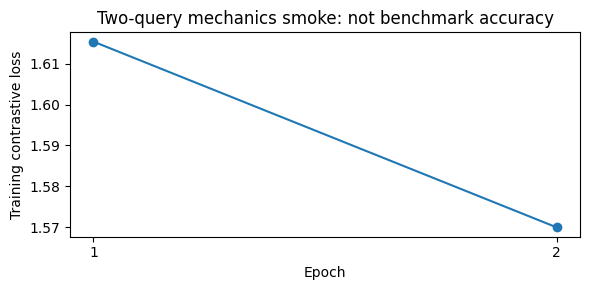

In [10]:
smoke_path=Path('data/interim/adapter-smoke-v1')
smoke=read(smoke_path/'result.json')
assert digest(smoke_path/'smoke.pt')==smoke['checkpoint_sha256']
data,cache_manifest=load_cache(CACHE,allow_smoke=True)
restored=Adapter();restored.load_state_dict(torch.load(smoke_path/'smoke.pt',weights_only=True,map_location='cpu'),strict=True);restored.eval()
torch.set_num_threads(2);torch.manual_seed(42)
replayed=Adapter();optimizer=torch.optim.AdamW(replayed.parameters(),lr=.001,weight_decay=.01)
item=data['train'];valid=item['positive'].any(dim=1);losses=[]
for epoch in range(2):
    optimizer.zero_grad();loss=multipositive_loss(replayed(item['x'][valid])@item['v'].T/.07,item['positive'][valid])
    loss.backward();optimizer.step();losses.append(float(loss.detach()))
replayed.eval()
with torch.inference_mode():delta=float((restored(data['val']['x'])-replayed(data['val']['x'])).abs().max())
assert delta<=1e-6
assert np.allclose(losses,smoke['losses'],atol=1e-6)
table([{'epoch':i+1,'recorded loss':old,'replayed loss':new} for i,(old,new) in enumerate(zip(smoke['losses'],losses))],'Actual two-query training replay')
print('Saved weight SHA256:',smoke['checkpoint_sha256'],'new checkpoint replay max abs error:',delta)
plt.figure(figsize=(6,3));plt.plot([1,2],losses,marker='o');plt.xticks([1,2]);plt.ylabel('Training contrastive loss');plt.xlabel('Epoch');plt.title('Two-query mechanics smoke: not benchmark accuracy');save_plot('adapter-smoke-loss')


## 6. Timestamp output without publishing captions
The next cell ranks actual cached validation vectors using the saved adapter. It shows only moment geometry, score and source-hash validity. Smoke examples are deliberately not presented as held-out accuracy.

In [11]:
with torch.inference_mode():scores=(restored(data['val']['x'])@data['val']['v'].T).numpy()
frames=read(CACHE/'frames.json');sources={r['video']:r['source_sha256'] for r in frames}
order=np.argsort(-scores[0],kind='stable')[:3]
table([{'rank':rank+1,'start seconds':5*data['val']['candidates'][i]['moment'][0],
        'end seconds':5*(data['val']['candidates'][i]['moment'][1]+1),'cosine':round(float(scores[0,i]),6),
        'source SHA recorded':len(sources[data['val']['candidates'][i]['video']])==64} for rank,i in enumerate(order)],'Actual cached smoke retrieval; no caption or media output')


rank,start seconds,end seconds,cosine,source SHA recorded
1,15,20,0.304014,True
2,15,25,0.303359,True
3,0,5,0.301701,True


## 7. Holdout boundary and next evidence
Test media were staged without descriptions or target intervals. The full study must freeze its selection before test text is encoded. Do not use the observed movie-demo test for new choices. Full learning curves, every seed and validation failure analysis will be added from verified completed outputs; no synthetic points or prospective scores are shown.

In [12]:
assert RUN_TEST is False
print('No test descriptions opened or scored by this notebook.')


No test descriptions opened or scored by this notebook.
